## Implicit Bathymetry Notebook

In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import fiona
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.image as mpimg
from matplotlib.colors import ListedColormap
from IPython.display import display


from implicit_bathy.config.config import DatasetConfig
from implicit_bathy.config.config import BayesianTrainingConfig, InferenceConfig

from implicit_bathy.preprocess.datasetSWOT import MultiDateLakeDataset

from implicit_bathy.train.trainer import BayesianTrainer
from implicit_bathy.inference import (
    PlotterCrossSection,
    PlotterDSM,
    PlotterErrorHistograms,
    PlotterVS,
    PlotterWaterProbaOnS2,
)
from implicit_bathy.inference.inference_classes import Processor, SimulateInputs

### Paths

In [ ]:
# The notebook inputs are stored in the data/ folder
nc_path = "/data/dataset.parquet"
# Path DSM
dsm_path = "/data/COP30.tif"
# Path S2
s2_path = "/data/S2.tif"
# Path S2
roi_gpkg = "/data/roi.gpkg"
# Path VT
vt_path = "/data/vt.csv"
# Path output
output_path = "/data/output_jupyter"

In [3]:
# Function plot png


def plot_png(im_path):
    img = mpimg.imread(im_path)
    plt.imshow(img)
    plt.axis("off")
    plt.show()

## Creation multi date dataset in pytorch format

In [4]:
# Creation multi date dataset in pytorch format

saving_path_data = Path(output_path) / "data"

dataset_params_pt = DatasetConfig(
    dataset_path=nc_path,
    roi_gpkg=roi_gpkg,
    id_feature_swot=2320106762,
    classes_to_keep=[1, 2, 3, 4],
    min_wse=376,
    max_wse=385,
    land_phase_shift=0.5,
    convert_to_crs="EPSG:32631",
    saving_path=saving_path_data / "dataset.pt",
)

m = MultiDateLakeDataset(dataset_params_pt)
m.create_dataset_from_gpkg()

INFO:root:- - - - - processing layer 20231122_6_570_71L
INFO:root:- - - - - processing layer 20240521_15_363_238R
INFO:root:- - - - - processing layer 20240227_11_363_238R
INFO:root:- - - - - processing layer 20240822_20_57_237L
INFO:root:- - - - - processing layer 20240820_19_570_71L
INFO:root:- - - - - processing layer 20240517_15_264_71R
INFO:root:- - - - - processing layer 20240902_20_363_238R
INFO:root:- - - - - processing layer 20230902_3_57_237L
INFO:root:- - - - - processing layer 20231216_8_57_237L
INFO:root:- - - - - processing layer 20240711_18_57_237L
INFO:root:- - - - - processing layer 20240216_11_57_237L
INFO:root:- - - - - processing layer 20240224_11_264_71R
INFO:root:- - - - - processing layer 20231012_4_570_71L
INFO:root:- - - - - processing layer 20240531_16_57_237L
INFO:root:- - - - - processing layer 20240730_18_570_71L
INFO:root:- - - - - processing layer 20240203_10_264_71R
INFO:root:- - - - - processing layer 20240426_14_264_71R
INFO:root:- - - - - processing l

## Ratio Water / Ground by time

In [5]:
t_values = np.unique(m.X[:, 2])

for time in t_values:
    _, _, classification_this_time, _, _ = m.select_input_from_dataset(time)
    nb_water = sum(classification_this_time == 4.0)
    nb_ground = sum(classification_this_time == 1.0)
    ratio = nb_ground / (nb_water + nb_ground)
    print(
        f"Ratio = {ratio.item():.2f} with {nb_water} water points and {nb_ground} ground points"
    )

Ratio = 0.10 with 1950 water points and 219 ground points
Ratio = 0.22 with 823 water points and 230 ground points
Ratio = 0.36 with 635 water points and 360 ground points
Ratio = 0.25 with 771 water points and 252 ground points
Ratio = 0.42 with 249 water points and 178 ground points
Ratio = 0.15 with 1382 water points and 240 ground points
Ratio = 0.41 with 450 water points and 309 ground points
Ratio = 0.25 with 721 water points and 236 ground points
Ratio = 0.33 with 526 water points and 260 ground points
Ratio = 0.43 with 414 water points and 316 ground points
Ratio = 0.29 with 716 water points and 288 ground points
Ratio = 0.20 with 855 water points and 220 ground points
Ratio = 0.14 with 1467 water points and 240 ground points
Ratio = 0.29 with 787 water points and 315 ground points
Ratio = 0.16 with 1612 water points and 310 ground points
Ratio = 0.20 with 1193 water points and 307 ground points
Ratio = 0.24 with 822 water points and 265 ground points
Ratio = 0.45 with 412 wate

## Plot water and ground by time in different cross section

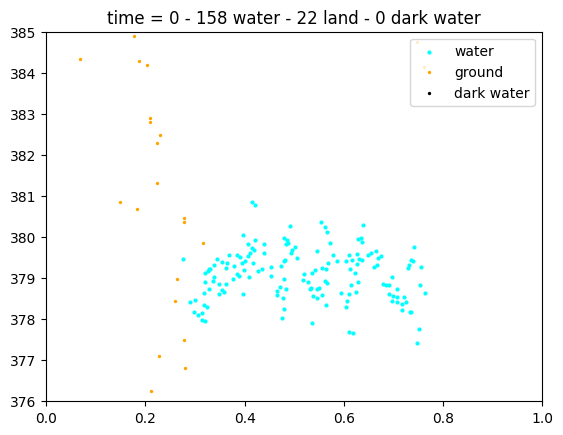

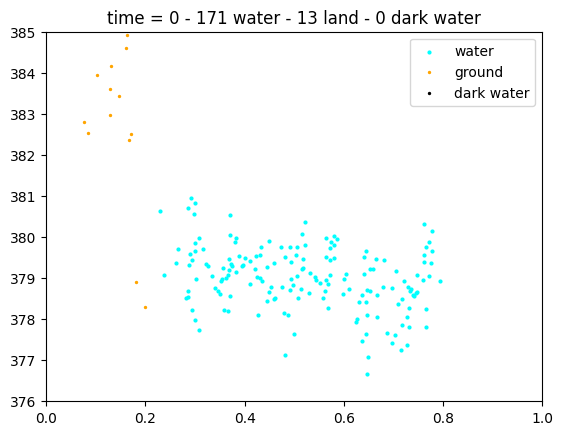

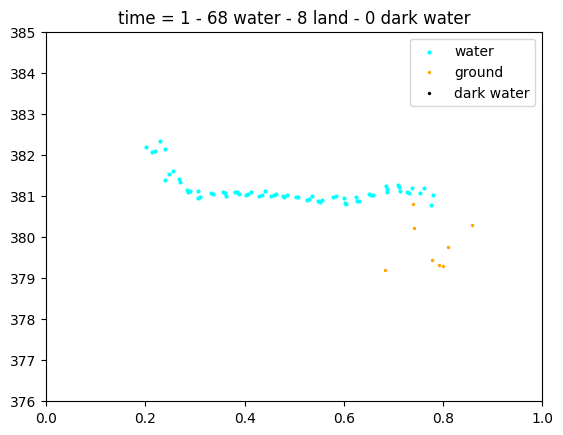

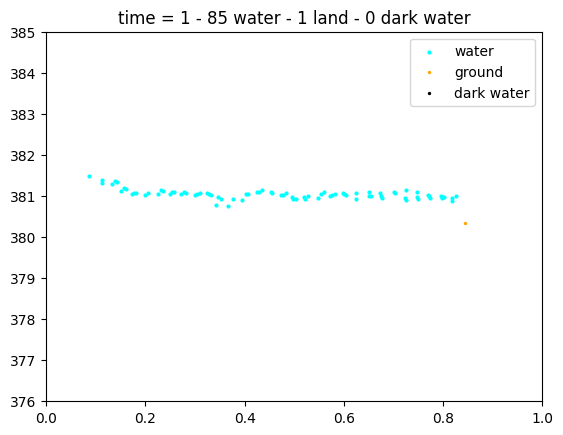

In [6]:
# Plot water and ground by time in different cross section
dim = "y"

for time in [0, 1]:
    for onset in [0.4, 0.6]:
        offset = onset + 0.05

        fig = plt.figure()
        ax = plt.gca()

        m.plot_data_slice(
            ax, onset, offset, dim, [time], with_classification=True
        )

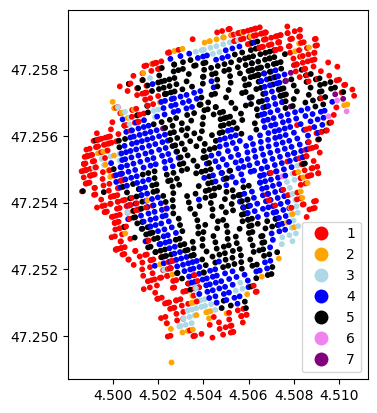

In [8]:
# Plot all points

gdf = gpd.read_parquet(nc_path)

first_layer = gdf["layer"].iloc[0]

gdf = gdf.loc[
    gdf["layer"] == first_layer
].copy()

cmap = ListedColormap(
    [
        "red",  # 1 ground
        "orange",  # 2 ground
        "lightblue",  # 3 water
        "blue",  # 4 water
        "black",  # 5 dark water
        "violet",  # 6
        "purple",  # 7
    ]
)

gdf["classification"] = gdf["classification"].astype(int)

ax = gdf.plot(
    column="classification",
    categorical=True,
    legend=True,
    cmap=cmap,
    markersize=10,
)

## Bayesian training

In [ ]:
saving_path_train = Path(output_path) / "train"

if not saving_path_train.exists():
    saving_path_train.mkdir()

config_params_bayesian = BayesianTrainingConfig(
    seed=3,
    monitor_every_epoch=10,
    dataset_path=saving_path_data / "dataset_classes_1_2_3_4.pt",
    save_path=Path(output_path) / "train",
    bayesian_model=True,
    ground_model="garf",
    ground_model_params=(16, 4, 0.1),
    water_model="mlp",
    water_model_params=(16, 4, None),
    lr=0.005,
    optimizer_name="Adam",
    n_epochs=10000,
    plot_every_epoch=1000,
    weighted_by_phase_noise=True,
    weighted_function="inverse",
    ground_prob="cauchy",
    wl_optimizer_name="AdamW",
    wl_lr=0.0005,
    confidence_threshold=0.999,
    n_epochs_wloss=5500,
    lambda_wloss=1,
    lambda_uncert=None,
)
t = BayesianTrainer(config_params_bayesian)
t.train(config_params_bayesian)

INFO:root:cpu
INFO:root:Seed 3 used.
INFO:root:Loading data from previously created PyTorch dataset.
INFO:root:Loading dataset :
INFO:root:torch.Size([111436, 3])


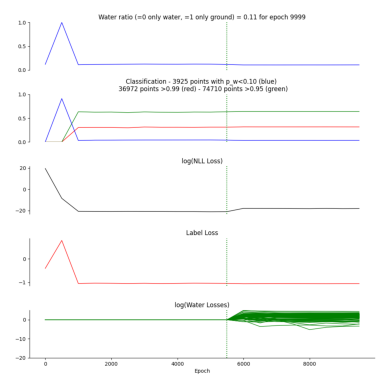

In [11]:
train_png = (
    Path(output_path)
    / "train"
    / "bayesian_GROUND-garf-w-16-d-4-sigma-0-1_WATER-mlp-w-16-d-4"
    / "bayesian_GROUND-garf-w-16-d-4-sigma-0-1_WATER-mlp-w-16-d-4_epoch9999.png"
)
train_pth = (
    Path(output_path)
    / "train"
    / "bayesian_GROUND-garf-w-16-d-4-sigma-0-1_WATER-mlp-w-16-d-4"
    / "bayesian_GROUND-garf-w-16-d-4-sigma-0-1_WATER-mlp-w-16-d-4_epoch9999.pth"
)
plot_png(train_png)

## Inference - different outputs

In [12]:
saving_path_inference = Path(output_path) / "inference"

if not saving_path_inference.exists():
    saving_path_inference.mkdir()

plot_params = InferenceConfig(
    dsm_path=dsm_path,
    vt_path=vt_path,
    start_time="03-08-2023",
    end_time="24-09-2024",
    swot_wse=[],
    dataset_dir=None,
    contour_path=roi_gpkg,
    convert_to_crs="EPSG:32631",
    dataset_path=saving_path_data / "dataset_classes_1_2_3_4.pt",
    plot_density=128,
    fig_size=5,
    id_feature_swot=2320106762,
    save_path_for_plots=saving_path_inference,
    max_wse_for_X_plot=410,
    min_wse_for_dsm=370,
    max_wse_for_dsm=400,
    model_path=train_pth,
    water_threshold_proba=0.99,
    ground_threshold_proba=0.1,
    plot_p_w_on_s1_images=False,
    save_s2_tif=False,
    save_s1_tif=False,
    deg_polyfit=2,
    surface_inference="bayesian",
    volume_inference="bayesian",
    p_w_filter=0.5,
    s2_tif_path=s2_path,
)

In [13]:
simulation = SimulateInputs()
dataset_params = DatasetConfig(
    dataset_path=saving_path_data / "dataset_classes_1_2_3_4.pt"
)
dataset = MultiDateLakeDataset(dataset_params)
dataset.load_dataset()
processor = Processor(plot_params, config_params_bayesian, dataset, simulation)

INFO:root:Simulating inputs
INFO:root:Loading data from previously created PyTorch dataset.


### Plot dsm

In [14]:
plotter_dsm = PlotterDSM(processor)
plotter_dsm.plot_dsm_water_z()

INFO:root:Load model bayesian_GROUND-garf-w-16-d-4-sigma-0-1_WATER-mlp-w-16-d-4
INFO:root:Model set to cpu


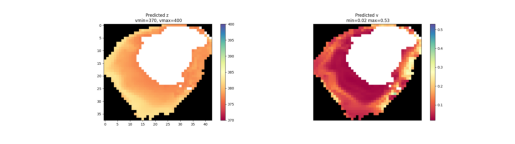

In [15]:
# Predicted height and predicted sigma
dsm_path = saving_path_inference / "predicted_DSM.png"
plot_png(dsm_path)

### Plot cross section

In [16]:
plotter_cross_section = PlotterCrossSection(processor)
plotter_cross_section.plot_many_cross_sections(t_values, "x")

INFO:root:Load model bayesian_GROUND-garf-w-16-d-4-sigma-0-1_WATER-mlp-w-16-d-4
INFO:root:Model set to cpu


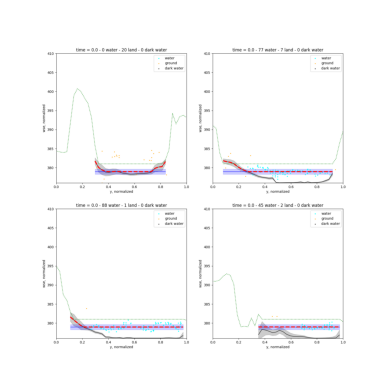

In [17]:
cross_section_path = (
    saving_path_inference
    / "plot_cross_section_width_0_02_x_time_0.000_2023-07-30.png"
)
plot_png(cross_section_path)

### Plot error histogramm

INFO:root:Load model bayesian_GROUND-garf-w-16-d-4-sigma-0-1_WATER-mlp-w-16-d-4
INFO:root:Model set to cpu


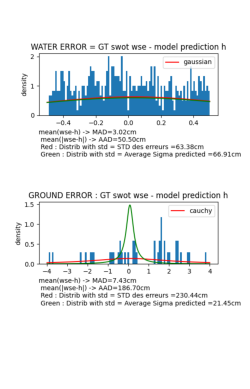

In [18]:
plotter_error_histrogram = PlotterErrorHistograms(processor)
plotter_error_histrogram.plot_all_error_histograms(t_values)

error_histo_path = (
    saving_path_inference / "error_histograms_time_0.000_2023-07-30.png"
)
plot_png(error_histo_path)

### Plot water proba on Sentinel 2

INFO:root:Load model bayesian_GROUND-garf-w-16-d-4-sigma-0-1_WATER-mlp-w-16-d-4
INFO:root:Model set to cpu
INFO:root:bounding box area is 1081011.129510963
INFO:root:OtsuThreshold: -0.07641855130687825
INFO:root:OtsuThreshold: -0.05628289930078009
INFO:root:OtsuThreshold: -0.10784050131214225
INFO:root:OtsuThreshold: -0.08550527610539264
INFO:root:OtsuThreshold: -0.060124969950140425
INFO:root:OtsuThreshold: -0.015379904383574533
INFO:root:OtsuThreshold: -0.015609251477010422
INFO:root:OtsuThreshold: -0.07217139976462825
INFO:root:OtsuThreshold: 0.004190774199266112
INFO:root:OtsuThreshold: -0.024332839576440557


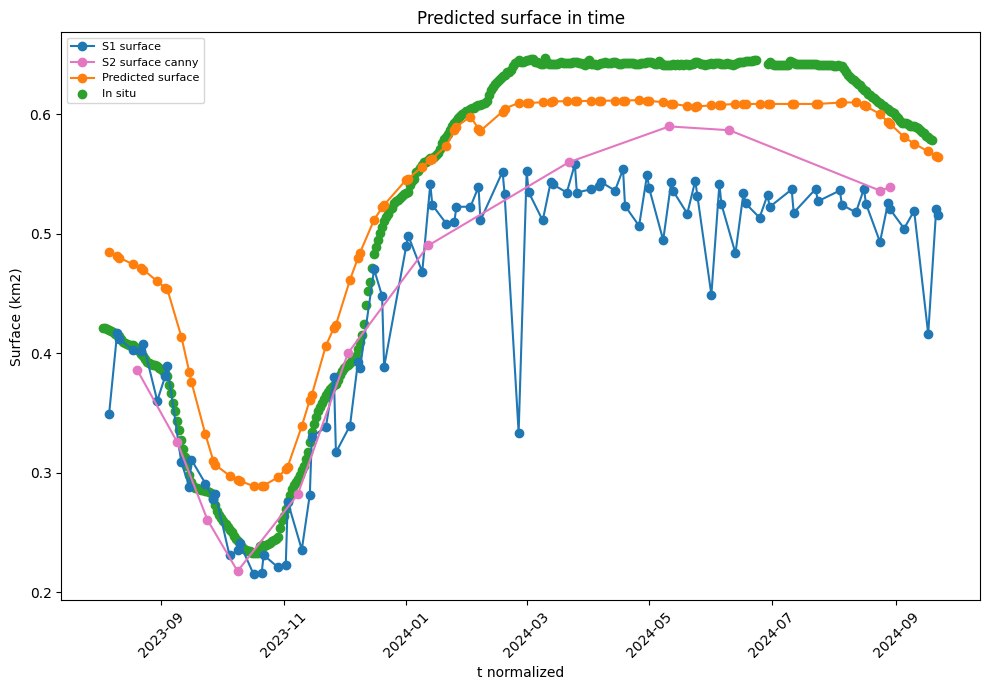

In [19]:
plotter_water_proba_on_s2 = PlotterWaterProbaOnS2(processor)
plotter_water_proba_on_s2.plot_water_proba_on_s2_images()

## Time serie height/area/volume

INFO:root:Load model bayesian_GROUND-garf-w-16-d-4-sigma-0-1_WATER-mlp-w-16-d-4
INFO:root:Model set to cpu
INFO:root:bounding box area is 1081011.129510963
INFO:root:Total volume = {9729100.165598668} m3


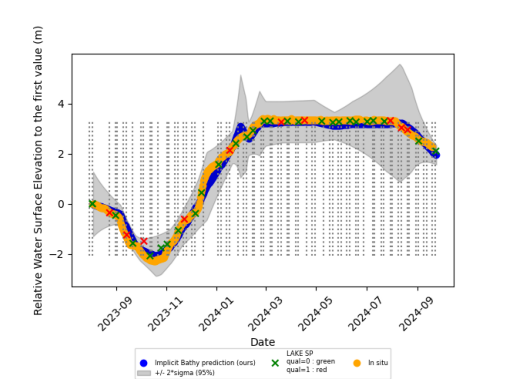

In [20]:
plotter_vs = PlotterVS(processor)
plotter_vs.get_data_vt()
plotter_vs.get_pred_data_t()
plotter_vs.get_swot_wse(t_values)
plotter_vs.plot_relative_wse_t_hydrocron()

wse_time_serie_path = (
    saving_path_inference
    / "relative_to_first_value_wse_time_serie_hydrocron.png"
)
plot_png(wse_time_serie_path)

INFO:root:bounding box area is 1081011.129510963
INFO:root:Total volume = {9729100.165598668} m3


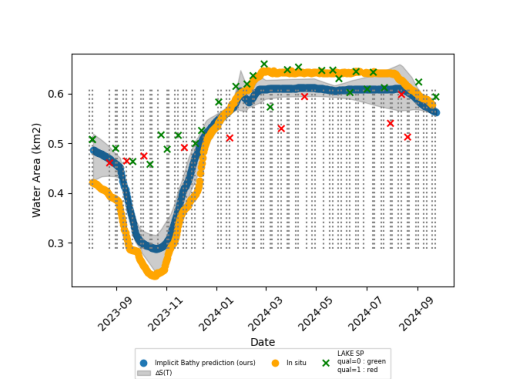

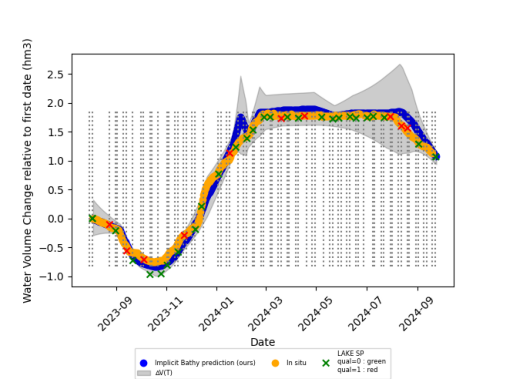

In [21]:
plotter_vs.get_data_vt()
plotter_vs.get_pred_data_t()
plotter_vs.get_swot_wse(t_values)
plotter_vs.plot_relative_wse_t()
plotter_vs.plot_absolute_wse_t(t_values)
plotter_vs.plot_absolute_wse_t_hydrocron()
plotter_vs.plot_surface_t_hydrocron()
plotter_vs.plot_volume_t()
plotter_vs.export_csv()
plotter_vs.compute_indicators()

surface_time_serie_path = (
    saving_path_inference / "absolute_surface_time_serie.png"
)
plot_png(surface_time_serie_path)
volume_time_serie_path = (
    saving_path_inference / "relative_volume_time_serie.png"
)
plot_png(volume_time_serie_path)

## Indicators
HC: Hydrocron indicators

Pred: prediction-based indicators

In [22]:
report_csv_path = Path(output_path) / "report.csv"
df = pd.read_csv(report_csv_path, index_col=0)
df.columns = ["indicators", "value"]
display(df)

,indicators,value
0,,
1,nb_points_pw_010,3925
2,nb_points_pw_099,36972
3,nb_points_pw_095,74710
4,nll_losses,-18.045824661181438
5,label_losses,-1.0598046779632568
6,water_losses,[ 1.0818355 3.9107099 1.7073894 0.837908...
7,mare_s2,0.1625
8,mare_s1,0.1858
9,quantile_abs_s2,0.1922
